## 1. Imports, data paths, and inversion settings

In [12]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from IPython.display import display
from scipy.interpolate import griddata
from scipy.ndimage import gaussian_filter

# Search upward for the shared project Data folder. Works when this notebook
# is in working_notebooks/ERT/ within the project repository.
NOTEBOOK_DIR = Path.cwd().resolve()
DATA_CANDIDATES = [p / "Data" for p in (NOTEBOOK_DIR, *NOTEBOOK_DIR.parents)]
DATA_DIR = next(
    (p for p in DATA_CANDIDATES if (p / "ERT data").is_dir() and (p / "DGPS data").is_dir()),
    None,
)
if DATA_DIR is None:
    raise FileNotFoundError(
        "Could not locate Data/ERT data and Data/DGPS data above the Jupyter "
        f"working directory: {NOTEBOOK_DIR}"
    )
ERT_DIR = DATA_DIR / "ERT data"
DGPS_DIR = DATA_DIR / "DGPS data"

# Specify the September 2026 DGPS survey file (not the October survey).
DGPS_CANDIDATE_NAMES = (
    "onyx_ert_92726.csv", "onyx_ert_092726.csv", "onyx ert 092726.csv"
)
DGPS_FILE = next(
    (DGPS_DIR / name for name in DGPS_CANDIDATE_NAMES if (DGPS_DIR / name).is_file()),
    None,
)
if DGPS_FILE is None:
    raise FileNotFoundError(
        f"Could not locate the 09/27/2026 DGPS CSV in {DGPS_DIR}. "
        f"Available CSVs: {[p.name for p in DGPS_DIR.glob('*.csv')]}\n"
        "Set DGPS_FILE explicitly if the file has a different name."
    )

# Only the two dipole–dipole datasets; gradient files are never opened.
def find_unique_dat(prefix):
    matches = sorted(ERT_DIR.glob(f"{prefix}*.dat"))
    if len(matches) != 1:
        raise FileNotFoundError(
            f"Expected exactly one {prefix}*.dat in {ERT_DIR}; "
            f"found {[p.name for p in matches]}"
        )
    return matches[0]

DAT_FILES = {
    1: find_unique_dat("DipoleDipole_1"),
    2: find_unique_dat("DipoleDipole_2"),
}

N_ELECTRODES = 64
SPACING_M = 1.5
RELATIVE_ERROR = 0.05          # Assumed 5% uncertainty in observed resistance
MEDIAN_FLOOR_FRACTION = 0.01   # Error floor = 1% of median absolute resistance
CELL_SIZE_M = 0.75             # Finest inversion mesh cell size (m)
MAX_ITERATIONS = 25

RUN_LINE1 = True
RUN_LINE2 = True

SAVE_FINAL_FIGURES = True      # Save only the two smoothed 2D inversion PNGs
FIGURE_DIR = NOTEBOOK_DIR      # Existing directory; no mkdir() anywhere

print("Working directory:", NOTEBOOK_DIR)
print("DGPS input:", DGPS_FILE)
for line, path in DAT_FILES.items():
    print(f"Dipole–dipole Line {line} input:", path)
print("Only final smoothed PNGs will be saved:", SAVE_FINAL_FIGURES)

Working directory: C:\Users\molly\work\Senior-Design-Geophysical-Characterization-of-Historic-Mine-Tunnels\working_notebooks\ERT
DGPS input: C:\Users\molly\work\Senior-Design-Geophysical-Characterization-of-Historic-Mine-Tunnels\Data\DGPS data\onyx_ert_92726.csv
Dipole–dipole Line 1 input: C:\Users\molly\work\Senior-Design-Geophysical-Characterization-of-Historic-Mine-Tunnels\Data\ERT data\DipoleDipole_1-2023-03-07-214954.dat
Dipole–dipole Line 2 input: C:\Users\molly\work\Senior-Design-Geophysical-Characterization-of-Historic-Mine-Tunnels\Data\ERT data\DipoleDipole_2-2023-03-07-214927.dat
Only final smoothed PNGs will be saved: True


## 2. Load DGPS and ABEM data directly (no processed CSV dependencies)

The original survey labeling is reversed relative to the ABEM electrode direction: `ert64` / `2ert64` correspond to ERT electrode 1. The known `2ert_shouldbe5` naming correction is performed **before** building Line 2. Nominal ABEM electrode x positions are in metres. The DGPS elevation is used for survey topography. Neither the gradient arrays nor their 0.5 m spacing are relevant here.

In [13]:
# -------- DGPS electrode profiles --------
dgps_raw = pd.read_csv(DGPS_FILE)
required_dgps = {"Name", "Longitude", "Latitude", "Ellipsoidal height"}
if not required_dgps.issubset(dgps_raw.columns):
    raise ValueError(f"DGPS columns missing: {sorted(required_dgps - set(dgps_raw.columns))}")


def correct_line2_labels(df):
    corrected = df.copy()
    corrected["Name"] = corrected["Name"].astype(str).str.strip()
    original = corrected["Name"].copy()
    if original.eq("2ert_shouldbe5").any():
        for i in range(5, 16):
            corrected.loc[original == f"2ert{i}", "Name"] = f"2ert{i+1}"
        corrected.loc[original == "2ert_shouldbe5", "Name"] = "2ert5"
        print("Applied Line 2 field-label correction.")
    return corrected


def build_dgps_profile(df, line):
    prefix = "ert" if line == 1 else "2ert"
    profile = df[df["Name"].str.fullmatch(rf"{prefix}\d+", na=False)].copy()
    if profile.empty:
        raise ValueError(f"Line {line}: no DGPS labels matching {prefix}1–{prefix}64")
    profile["dgps_point"] = profile["Name"].str.extract(r"(\d+)$")[0].astype(int)
    profile["electrode"] = N_ELECTRODES + 1 - profile["dgps_point"]
    profile["distance_m"] = (profile["electrode"] - 1) * SPACING_M
    profile["elevation_m"] = pd.to_numeric(profile["Ellipsoidal height"], errors="coerce")
    for name in ("Latitude", "Longitude"):
        profile[name] = pd.to_numeric(profile[name], errors="coerce")
    profile = profile.sort_values("electrode").reset_index(drop=True)
    if profile["electrode"].duplicated().any():
        raise ValueError(f"Line {line}: duplicate DGPS electrodes")
    if profile["electrode"].min() != 1 or profile["electrode"].max() != N_ELECTRODES:
        raise ValueError(f"Line {line}: missing an endpoint electrode")
    if profile[["elevation_m", "Longitude", "Latitude"]].isna().any().any():
        raise ValueError(f"Line {line}: non-numeric DGPS coordinates or height")
    if len(profile) != N_ELECTRODES:
        raise ValueError(f"Line {line}: expected 64 unique DGPS electrodes, got {len(profile)}")
    expected_first = "ert64" if line == 1 else "2ert64"
    expected_last = "ert1" if line == 1 else "2ert1"
    if (profile.iloc[0]["Name"] != expected_first or
            profile.iloc[-1]["Name"] != expected_last):
        raise ValueError(f"Line {line}: reversed electrode/DGPS mapping failed")
    return profile


dgps = correct_line2_labels(dgps_raw)
profiles = {line: build_dgps_profile(dgps, line) for line in (1, 2)}

# -------- RES2DINV general-array ABEM 10-column format --------
ABEM_COLUMNS = [
    "n_elec", "A_x", "A_z", "B_x", "B_z",
    "M_x", "M_z", "N_x", "N_z", "resistance",
]


def read_abem_dat(filepath):
    lines = filepath.read_text(encoding="utf-8", errors="replace").splitlines()
    if len(lines) < 10:
        raise ValueError(f"ABEM file header too short: {filepath}")
    try:
        header = {
            "spacing_m": float(lines[1].strip()),
            "array_code": int(lines[2].strip()),
            "measurement_type": int(lines[5].strip()),
            "n_measurements": int(lines[6].strip()),
            "x_location_type": int(lines[7].strip()),
        }
    except (ValueError, IndexError) as exc:
        raise ValueError(f"Unrecognized ABEM header in {filepath.name}") from exc
    if header["array_code"] != 11 or header["measurement_type"] != 1:
        raise ValueError(
            f"{filepath.name}: expected general array 11 and resistance data (type 1); "
            f"found {header}"
        )
    if not np.isclose(header["spacing_m"], SPACING_M):
        raise ValueError(f"{filepath.name}: electrode spacing differs from {SPACING_M} m")
    rows = []
    for line_number, text in enumerate(lines[9:9 + header["n_measurements"]], start=10):
        try:
            vals = [float(v) for v in text.split()]
        except ValueError as exc:
            raise ValueError(f"Non-numeric ABEM row {line_number}") from exc
        if len(vals) != 10:
            raise ValueError(f"Expected 10 columns at ABEM row {line_number}; found {len(vals)}")
        rows.append(vals)
    if len(rows) != header["n_measurements"]:
        raise ValueError(f"{filepath.name}: incomplete measurement records")
    out = pd.DataFrame(rows, columns=ABEM_COLUMNS)
    return out, header


def calculate_apparent_resistivity(df):
    out = df.copy()
    def distance(p, q):
        return np.hypot(out[f"{p}_x"] - out[f"{q}_x"],
                        out[f"{p}_z"] - out[f"{q}_z"])
    with np.errstate(divide="ignore", invalid="ignore"):
        g = (1 / distance("A", "M") - 1 / distance("A", "N")
             - 1 / distance("B", "M") + 1 / distance("B", "N"))
        out["K"] = 2 * np.pi / g
        out["apparent_resistivity"] = out["K"] * out["resistance"]
    ab_mid = (out["A_x"] + out["B_x"]) / 2
    mn_mid = (out["M_x"] + out["N_x"]) / 2
    out["distance_m"] = (ab_mid + mn_mid) / 2
    out["pseudo_depth_m"] = np.abs(ab_mid - mn_mid) / 2
    return out


raw_data, headers = {}, {}
for line in (1, 2):
    raw, headers[line] = read_abem_dat(DAT_FILES[line])
    raw_data[line] = calculate_apparent_resistivity(raw)
    print(f"Line {line}: {len(raw_data[line])} measurements; "
          f"{len(profiles[line])} surveyed electrodes; "
          f"ABEM measurement type={headers[line]['measurement_type']}")
    if headers[line]["x_location_type"] == 2:
        print(f"  CAUTION: Line {line} ABEM x may mean along-surface distance, "
              "not horizontal distance. Verify before geometric interpretation.")
    elif headers[line]["x_location_type"] != 1:
        print(f"  CAUTION: Line {line} has unusual ABEM x-location type "
              f"{headers[line]['x_location_type']}.")

Applied Line 2 field-label correction.
Line 1: 1980 measurements; 64 surveyed electrodes; ABEM measurement type=1
  CAUTION: Line 1 ABEM x may mean along-surface distance, not horizontal distance. Verify before geometric interpretation.
Line 2: 1980 measurements; 64 surveyed electrodes; ABEM measurement type=1
  CAUTION: Line 2 ABEM x may mean along-surface distance, not horizontal distance. Verify before geometric interpretation.


## 3. Quality control (display only; nothing saved)

Line 1: 1980 / 1980 accepted; 0 excluded
Line 2: 1980 / 1980 accepted; 0 excluded


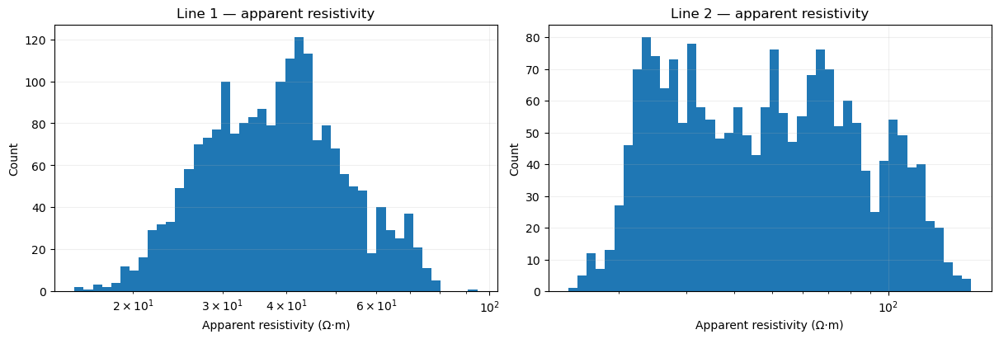

In [14]:
# Zero-based row indices to exclude ONLY after checking original ABEM measurements.
EXCLUDE_ROWS = {1: [], 2: []}


def quality_control(df, line):
    df = df.copy().reset_index(drop=True)
    df["original_row"] = np.arange(len(df))
    resistance = df["resistance"].to_numpy(dtype=float)
    factor = df["K"].to_numpy(dtype=float)
    rho_a = df["apparent_resistivity"].to_numpy(dtype=float)

    valid = np.isfinite(resistance) & (resistance > 0)
    valid &= np.isfinite(factor) & (factor > 0)
    valid &= np.isfinite(rho_a) & (rho_a > 0)
    for electrode in "ABMN":
        x = df[f"{electrode}_x"].to_numpy(dtype=float)
        valid &= np.isfinite(x) & (x >= -1e-6) & (x <= 63 * SPACING_M + 1e-6)
        valid &= np.isclose(x / SPACING_M, np.round(x / SPACING_M), atol=1e-5)

    if not np.allclose(rho_a[valid], (factor * resistance)[valid], rtol=1e-5, atol=1e-7):
        raise AssertionError(f"Line {line}: resistance/geometric-factor calculation mismatch")
    valid &= ~df["original_row"].isin(EXCLUDE_ROWS[line]).to_numpy()

    accepted_df = df.loc[valid].copy().reset_index(drop=True)
    if len(accepted_df) < 100:
        raise ValueError(f"Line {line}: only {len(accepted_df)} usable measurements")
    print(f"Line {line}: {len(accepted_df)} / {len(df)} accepted; "
          f"{len(df)-len(accepted_df)} excluded")
    if (~valid).any():
        display(df.loc[~valid, ["original_row", "resistance", "K",
                                "apparent_resistivity"]].head(15))
    return accepted_df


accepted = {line: quality_control(raw_data[line], line) for line in (1, 2)}

fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for ax, line in zip(axes, (1, 2)):
    values = accepted[line]["apparent_resistivity"].to_numpy()
    ax.hist(values, bins=np.geomspace(values.min(), values.max(), 45))
    ax.set(xscale="log", title=f"Line {line} — apparent resistivity",
           xlabel="Apparent resistivity (Ω·m)", ylabel="Count")
    ax.grid(alpha=0.2)
plt.show()  # Display only; no export

## 4. DGPS topography and electrode locations (display only)

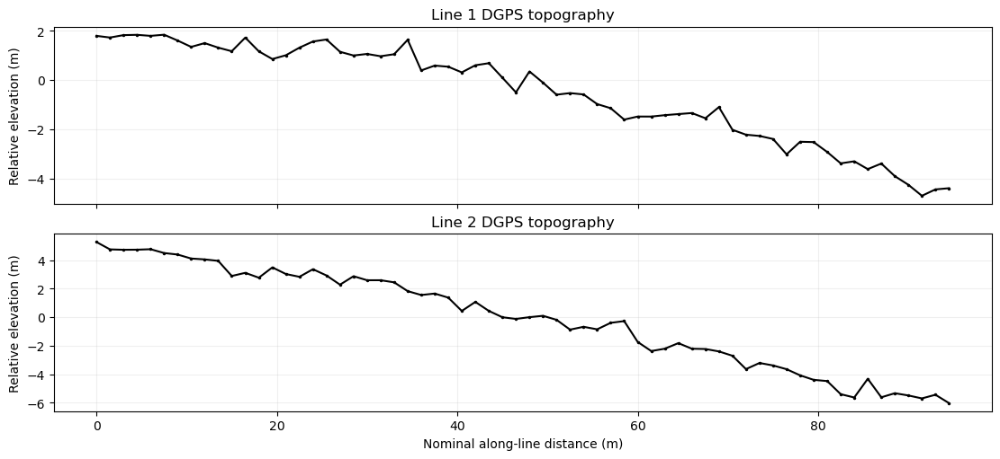

In [15]:
def make_electrodes(df, profile, electrode, datum):
    x = df[f"{electrode}_x"].to_numpy(dtype=float)
    z = np.interp(x, profile["distance_m"], profile["elevation_m"]) - datum
    return np.c_[x, z]


def build_geometry(line):
    df, profile = accepted[line], profiles[line]
    datum = float(np.median(profile["elevation_m"]))
    topo = np.c_[profile["distance_m"].to_numpy(dtype=float),
                 profile["elevation_m"].to_numpy(dtype=float) - datum]
    coords = {electrode: make_electrodes(df, profile, electrode, datum)
              for electrode in "ABMN"}
    if any(not np.isfinite(c).all() for c in coords.values()):
        raise ValueError(f"Line {line}: invalid electrode coordinates")
    for pair in ("AB", "MN"):
        if np.any(np.linalg.norm(coords[pair[0]] - coords[pair[1]], axis=1) < 0.1):
            raise ValueError(f"Line {line}: coincident {pair} electrodes")
    return {"df": df, "topo": topo, "coords": coords, "datum": datum}


geometry = {line: build_geometry(line) for line in (1, 2)}
fig, axes = plt.subplots(2, 1, figsize=(11, 5), sharex=True, constrained_layout=True)
for ax, line in zip(axes, (1, 2)):
    topo = geometry[line]["topo"]
    ax.plot(topo[:, 0], topo[:, 1], "k.-", markersize=3)
    ax.set(title=f"Line {line} DGPS topography", ylabel="Relative elevation (m)")
    ax.grid(alpha=0.2)
axes[-1].set_xlabel("Nominal along-line distance (m)")
plt.show()  # Display only; no export

## 5. Build SimPEG surveys and inverse-problem functions

Both inversions use the same SimPEG **2.5D DC-resistivity** formulation, topographic TreeMesh, smoothness regularization, and measured **resistance V/I in Ω** (entered as `volt` for unit current) as the existing notebook. The ABEM flat-earth geometric factor is used for QC only. No percentile-based measurements are automatically removed. Noise values below are assumptions, not measured reciprocal errors.

In [16]:
try:
    import simpeg
    from simpeg import (maps, data, data_misfit, regularization, optimization,
                        inverse_problem, inversion, directives)
    from simpeg.electromagnetics.static import resistivity as dc
    from simpeg.electromagnetics.static.utils import generate_survey_from_abmn_locations
    from discretize import TreeMesh
    from discretize.utils import active_from_xyz
except ImportError as exc:
    raise ImportError(
        "SimPEG is not installed in this kernel. Run %pip install simpeg discretize "
        "pymatsolver in a separate cell, then restart this kernel."
    ) from exc

print("SimPEG version:", simpeg.__version__)


def build_simpeg_survey(geom, line):
    xyz = geom["coords"]
    survey, sort_index = generate_survey_from_abmn_locations(
        locations_a=xyz["A"], locations_b=xyz["B"],
        locations_m=xyz["M"], locations_n=xyz["N"],
        data_type="volt", output_sorting=True,
    )
    ordered = geom["df"].iloc[sort_index].copy().reset_index(drop=True)
    r = ordered["resistance"].to_numpy(dtype=float)
    floor = MEDIAN_FLOOR_FRACTION * float(np.median(np.abs(r)))
    std = RELATIVE_ERROR * np.abs(r) + floor
    obs = data.Data(survey, dobs=r)
    obs.standard_deviation = std
    if survey.nD != len(r):
        raise ValueError(f"Line {line}: ABMN data order mismatch")
    print(f"Line {line}: {survey.nD} resistance data; error assumption "
          f"{100*RELATIVE_ERROR:.0f}% |R| + {floor:.4g} Ω floor")
    return {"survey": survey, "obs": obs, "ordered": ordered}


surveys = {line: build_simpeg_survey(geometry[line], line) for line in (1, 2)}


def make_mesh_and_active(geom, survey):
    topo = geom["topo"]
    dh = CELL_SIZE_M
    nx, nz = 512, 256
    dom_x, dom_z = nx * dh, nz * dh
    x_center = 0.5 * (topo[:, 0].min() + topo[:, 0].max())
    x0 = x_center - dom_x / 2
    z0 = float(topo[:, 1].max() + 10 - dom_z)
    mesh = TreeMesh([[(dh, nx)], [(dh, nz)]], x0=[x0, z0], diagonal_balance=True)
    topo_extended = np.vstack([
        [x0 + dh, topo[0, 1]],
        topo,
        [x0 + dom_x - dh, topo[-1, 1]],
    ])
    mesh.refine_surface(topo_extended, padding_cells_by_level=[0, 0, 4, 4], finalize=False)
    mesh.refine_points(survey.unique_electrode_locations,
                       padding_cells_by_level=[1, 2, 3, 3], finalize=False)
    mesh.finalize()
    active = active_from_xyz(mesh, topo_extended)
    if active.sum() < 100:
        raise RuntimeError("Not enough active mesh cells")
    # Compatible with the SimPEG API in the existing gpgn-318 environment.
    survey.drape_electrodes_on_topography(mesh, active)
    return mesh, active


def make_inverse_problem(line):
    geom = geometry[line]
    prepared = surveys[line]
    survey, obs = prepared["survey"], prepared["obs"]
    mesh, active = make_mesh_and_active(geom, survey)
    n_active = int(active.sum())
    rho_background = float(np.median(prepared["ordered"]["apparent_resistivity"]))
    m0 = np.full(n_active, np.log(1.0 / rho_background))  # log conductivity
    sigma_map = maps.InjectActiveCells(mesh, active, 1e-8) * maps.ExpMap(nP=n_active)
    sim = dc.simulation_2d.Simulation2DNodal(
        mesh, survey=survey, sigmaMap=sigma_map, storeJ=True
    )
    misfit = data_misfit.L2DataMisfit(simulation=sim, data=obs)
    reg = regularization.WeightedLeastSquares(
        mesh, active_cells=active, alpha_s=CELL_SIZE_M**-2,
        alpha_x=1.0, alpha_y=1.0, reference_model=m0.copy(),
        reference_model_in_smooth=False,
    )
    optimizer = optimization.InexactGaussNewton(
        maxIter=MAX_ITERATIONS, maxIterLS=20, maxIterCG=20, tolCG=1e-3,
    )
    problem = inverse_problem.BaseInvProblem(misfit, reg, optimizer)
    inv = inversion.BaseInversion(problem, directiveList=[
        directives.UpdateSensitivityWeights(every_iteration=True, threshold_value=1e-2),
        directives.UpdatePreconditioner(update_every_iteration=True),
        directives.BetaEstimate_ByEig(beta0_ratio=10),
        directives.BetaSchedule(coolingFactor=2.0, coolingRate=2),
        directives.TargetMisfit(chifact=1.0),
    ])
    print(f"Line {line}: {mesh.n_cells} mesh cells; {n_active} active; "
          f"starting ρ={rho_background:.2f} Ω·m")
    return {"mesh": mesh, "active": active, "sim": sim, "obs": obs,
            "inverse": inv, "m0": m0, "background_rho": rho_background}

SimPEG version: 0.24.0
Line 1: 1980 resistance data; error assumption 5% |R| + 0.0003125 Ω floor
Line 2: 1980 resistance data; error assumption 5% |R| + 0.0003853 Ω floor


C:\Users\molly\AppData\Local\Temp\ipykernel_7116\3604471692.py:20: UserWarning: Ordering of ABMN locations changed when generating survey. Associated data vectors will need sorting. Set output_sorting to True for sorting indices.
  survey, sort_index = generate_survey_from_abmn_locations(


## 6. Run Line 1 inversion

**Computationally expensive:** this may take significant time. Once complete, keep the kernel running and do not rerun this cell to change colors, smoothness, or camera angle.

In [17]:
results = {}


def solve_line(line):
    fitted = make_inverse_problem(line)
    recovered = fitted["inverse"].run(fitted["m0"])
    fitted["m_recovered"] = recovered
    fitted["predicted_R"] = fitted["sim"].dpred(recovered)
    results[line] = fitted
    return fitted


if RUN_LINE1:
    print("\n--- Inverting Dipole–Dipole Line 1 ---")
    solve_line(1)
else:
    print("Line 1 disabled. Change RUN_LINE1 to True in configuration.")


--- Inverting Dipole–Dipole Line 1 ---
Line 1: 3332 mesh cells; 1678 active; starting ρ=38.36 Ω·m

Running inversion with SimPEG v0.24.0

                        simpeg.InvProblem is setting bfgsH0 to the inverse of the eval2Deriv.
                        ***Done using same Solver, and solver_opts as the Simulation2DNodal problem***
                        


C:\Users\molly\anaconda3\envs\gpgn-318\Lib\site-packages\simpeg\base\pde_simulation.py:490: DefaultSolverWarning: Using the default solver: Pardiso. 

If you would like to suppress this notification, add 
warnings.filterwarnings('ignore', simpeg.utils.solver_utils.DefaultSolverWarning)
 to your script.
  return get_default_solver(warn=True)
C:\Users\molly\anaconda3\envs\gpgn-318\Lib\site-packages\pymatsolver\solvers.py:415: FutureWarning: In Future pymatsolver v0.4.0, passing a vector of shape (n, 1) to the solve method will return an array with shape (n, 1), instead of always returning a flattened array. This is to be consistent with numpy.linalg.solve broadcasting.
  return self.solve(val)


model has any nan: 0
============================ Inexact Gauss Newton ============================
  #     beta     phi_d     phi_m       f      |proj(x-g)-x|  LS    Comment   
-----------------------------------------------------------------------------
x0 has any nan: 0
   0  3.44e+03  1.88e+05  0.00e+00  1.88e+05    6.10e+04      0              
   1  3.44e+03  5.71e+04  1.12e+01  9.58e+04    1.57e+04      0              
   2  1.72e+03  5.41e+04  1.10e+01  7.31e+04    5.35e+03      0              
   3  1.72e+03  4.14e+04  1.75e+01  7.16e+04    1.44e+03      0              
   4  8.61e+02  4.38e+04  1.57e+01  5.73e+04    6.09e+03      0              
   5  8.61e+02  2.97e+04  2.97e+01  5.53e+04    1.76e+03      0              
   6  4.30e+02  3.25e+04  2.49e+01  4.32e+04    4.57e+03      0              
   7  4.30e+02  2.20e+04  4.51e+01  4.14e+04    1.47e+03      0              
   8  2.15e+02  2.35e+04  3.80e+01  3.17e+04    3.42e+03      0              
   9  2.15e+02  1.56e+04

## 7. Run Line 2 inversion independently

In [18]:
if RUN_LINE2:
    print("\n--- Inverting Dipole–Dipole Line 2 ---")
    solve_line(2)
else:
    print("Line 2 disabled. Change RUN_LINE2 to True in configuration.")


--- Inverting Dipole–Dipole Line 2 ---
Line 2: 3410 mesh cells; 2052 active; starting ρ=47.98 Ω·m

Running inversion with SimPEG v0.24.0

                        simpeg.InvProblem is setting bfgsH0 to the inverse of the eval2Deriv.
                        ***Done using same Solver, and solver_opts as the Simulation2DNodal problem***
                        


C:\Users\molly\anaconda3\envs\gpgn-318\Lib\site-packages\simpeg\electromagnetics\static\resistivity\simulation_2d.py:768: RuntimeWarning: invalid value encountered in divide
  r_hat = r_vec / r[:, None]
C:\Users\molly\anaconda3\envs\gpgn-318\Lib\site-packages\simpeg\electromagnetics\static\resistivity\simulation_2d.py:795: RuntimeWarning: invalid value encountered in divide
  alpha[not_top] = (ky * k1e(ky * r) / k0e(ky * r) * r_dot_n)[not_top]


model has any nan: 0
============================ Inexact Gauss Newton ============================
  #     beta     phi_d     phi_m       f      |proj(x-g)-x|  LS    Comment   
-----------------------------------------------------------------------------
x0 has any nan: 0
   0  7.23e+03  3.90e+05  0.00e+00  3.90e+05    1.24e+05      0              
   1  7.23e+03  1.37e+05  8.14e+00  1.96e+05    5.72e+04      0              
   2  3.61e+03  8.88e+04  1.36e+01  1.38e+05    5.88e+03      0   Skip BFGS  
   3  3.61e+03  7.65e+04  1.77e+01  1.40e+05    2.35e+03      0   Skip BFGS  
   4  1.81e+03  8.16e+04  1.58e+01  1.10e+05    1.06e+04      0              
   5  1.81e+03  5.26e+04  3.11e+01  1.09e+05    3.28e+03      0              
   6  9.03e+02  5.97e+04  2.56e+01  8.29e+04    7.63e+03      0              
   7  9.03e+02  3.92e+04  4.71e+01  8.17e+04    2.43e+03      0              
   8  4.52e+02  4.38e+04  3.94e+01  6.16e+04    5.27e+03      0              
   9  4.52e+02  3.01e+04

## 8. Inversion diagnostics (display only)

The normalized residual is `(observed − predicted) / assumed_std`. RMS near 1 is desirable only if the assigned uncertainties are realistic. The right-hand plot uses **pseudodepth for layout**, not true inverted model depth. These checks are displayed, **never saved**.

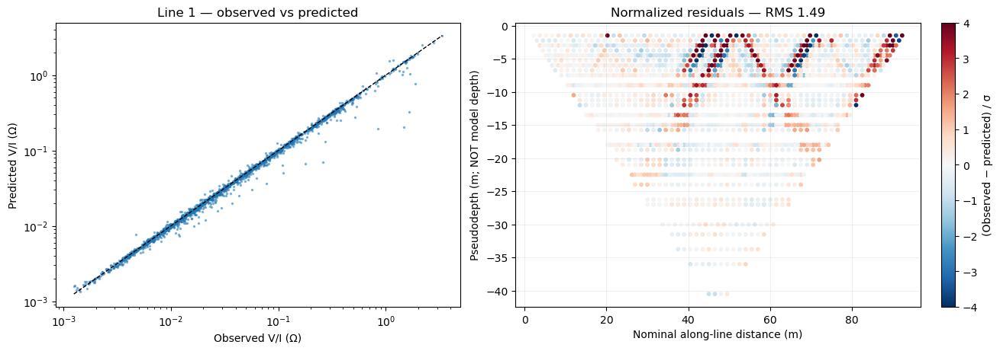

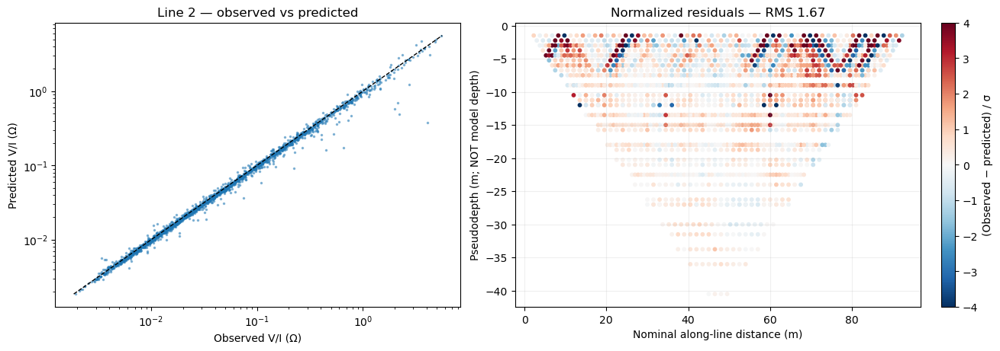

,Line,Number of data,Normalized RMS,Chi² / N
0,1,1980,1.492,2.226
1,2,1980,1.670,2.789


In [19]:
summary_rows = []
for line in (1, 2):
    if line not in results:
        continue
    out = results[line]
    obs = out["obs"].dobs
    pred = out["predicted_R"]
    std = out["obs"].standard_deviation
    resid = (obs - pred) / std
    rms = float(np.sqrt(np.mean(resid**2)))
    ordered = surveys[line]["ordered"]
    summary_rows.append({"Line": line, "Number of data": len(obs),
                         "Normalized RMS": rms, "Chi² / N": rms**2})

    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)
    positive = (obs > 0) & (pred > 0)
    if positive.any():
        low = min(obs[positive].min(), pred[positive].min())
        high = max(obs[positive].max(), pred[positive].max())
        axes[0].loglog(obs[positive], pred[positive], ".", ms=3, alpha=0.45)
        axes[0].plot([low, high], [low, high], "k--", lw=1)
    else:
        axes[0].scatter(obs, pred, s=6)
    axes[0].set(title=f"Line {line} — observed vs predicted",
                xlabel="Observed V/I (Ω)", ylabel="Predicted V/I (Ω)")
    scatter = axes[1].scatter(
        ordered["distance_m"], -ordered["pseudo_depth_m"],
        c=resid, s=10, cmap="RdBu_r", vmin=-4, vmax=4,
    )
    axes[1].set(title=f"Normalized residuals — RMS {rms:.2f}",
                xlabel="Nominal along-line distance (m)",
                ylabel="Pseudodepth (m; NOT model depth)")
    axes[1].grid(alpha=0.2)
    fig.colorbar(scatter, ax=axes[1], label="(Observed − predicted) / σ")
    plt.show()  # No file saved

if summary_rows:
    display(pd.DataFrame(summary_rows).round(3))

## 9. Final smoothed 2D inverted-resistivity sections — **the only automatic saved figures**

Plots are interpolated onto a fine display grid and lightly Gaussian-smoothed in **log resistivity**. This changes *only the appearance*, not the inversion result. Both sections use a shared logarithmic color scale. The white region is above the DGPS surface; the plotted window extends 20 m vertically below each surface location. Low-sensitivity regions are **not masked by sensitivity** and should not be interpreted as well resolved.

If you change `DISPLAY_DEPTH_M`, `SMOOTH_X_M`, `SMOOTH_Z_M`, or the colormap, **rerun only this cell and the 3D cell**. Each saved PNG is overwritten rather than generating numbered duplicates.

Saved final figure: C:\Users\molly\work\Senior-Design-Geophysical-Characterization-of-Historic-Mine-Tunnels\working_notebooks\ERT\Onyx_Line1_Smoothed_Inversion.png


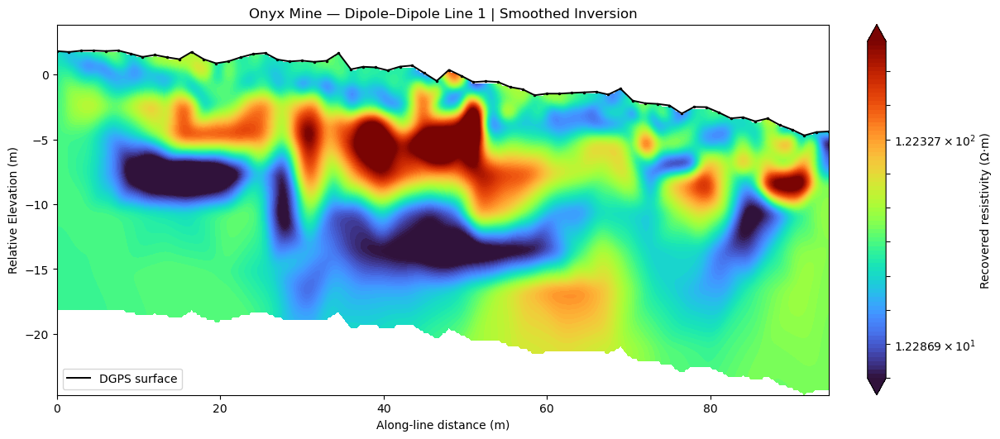

Saved final figure: C:\Users\molly\work\Senior-Design-Geophysical-Characterization-of-Historic-Mine-Tunnels\working_notebooks\ERT\Onyx_Line2_Smoothed_Inversion.png


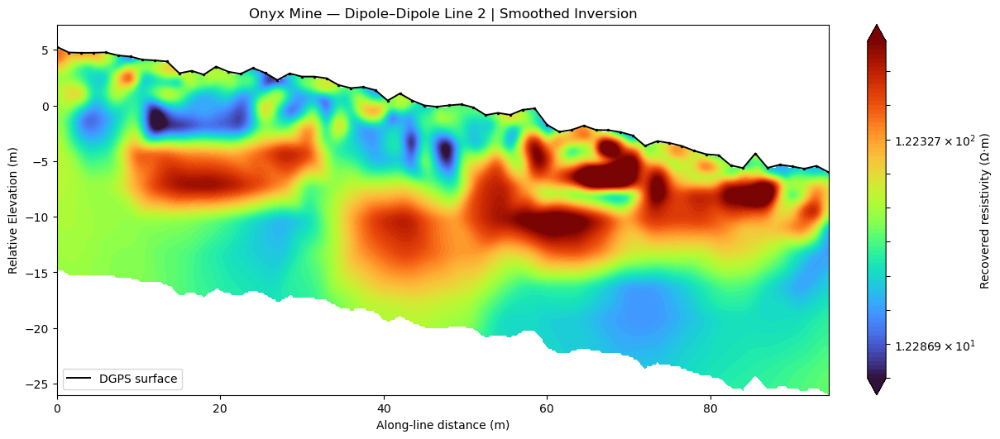

In [23]:
DISPLAY_DEPTH_M = 20.0
SMOOTH_X_M = 0.7
SMOOTH_Z_M = 0.4
GRID_DX_M = 0.25
GRID_DZ_M = 0.20
CMAP = "turbo"


def interpolated_section(line):
    out = results[line]
    topo = geometry[line]["topo"]
    centers = out["mesh"].cell_centers[out["active"]]
    log_rho = -out["m_recovered"] / np.log(10.0)
    x = np.arange(topo[:, 0].min(), topo[:, 0].max() + GRID_DX_M, GRID_DX_M)
    z = np.arange(topo[:, 1].min() - DISPLAY_DEPTH_M,
                  topo[:, 1].max() + 2 + GRID_DZ_M, GRID_DZ_M)
    X, Z = np.meshgrid(x, z)
    values = griddata(centers, log_rho, (X, Z), method="linear")
    missing = ~np.isfinite(values)
    if missing.any():
        values[missing] = griddata(centers, log_rho,
                                   (X[missing], Z[missing]), method="nearest")
    surface = np.interp(x, topo[:, 0], topo[:, 1])[None, :]
    inside = (Z <= surface) & (Z >= surface - DISPLAY_DEPTH_M)
    sigma = (SMOOTH_Z_M / GRID_DZ_M, SMOOTH_X_M / GRID_DX_M)
    weights = gaussian_filter(inside.astype(float), sigma=sigma)
    smoothed = gaussian_filter(np.where(inside, values, 0), sigma=sigma)
    smoothed /= np.maximum(weights, 1e-8)
    rho = np.ma.array(10**smoothed, mask=~inside)
    return X, Z, rho


if not all(line in results for line in (1, 2)):
    raise RuntimeError("Run both inversions before the final comparison figures.")

sections_2d = {line: interpolated_section(line) for line in (1, 2)}
valid_rho = np.concatenate([sections_2d[line][2].compressed() for line in (1, 2)])
color_min, color_max = np.percentile(valid_rho, [2, 98])
color_min = max(float(color_min), 1e-3)
color_max = max(float(color_max), color_min * 1.01)
shared_norm = LogNorm(vmin=color_min, vmax=color_max)
shared_levels = np.geomspace(color_min, color_max, 80)

# Exactly two files: one per inverted line. All other figures display only.
for line in (1, 2):
    X, Z, rho = sections_2d[line]
    topo = geometry[line]["topo"]
    fig, ax = plt.subplots(figsize=(12, 5.2), constrained_layout=True)
    cf = ax.contourf(X, Z, rho, levels=shared_levels, norm=shared_norm,
                     cmap=CMAP, extend="both")
    ax.plot(topo[:, 0], topo[:, 1], "k-", lw=1.4, label="DGPS surface")
    ax.plot(topo[:, 0], topo[:, 1], "k.", ms=3)
    ax.set(title=f"Onyx Mine — Dipole–Dipole Line {line} | Smoothed Inversion",
           xlabel="Along-line distance (m)",
           ylabel="Relative Elevation (m)",
           xlim=(topo[:, 0].min(), topo[:, 0].max()),
           ylim=(topo[:, 1].min() - DISPLAY_DEPTH_M, topo[:, 1].max() + 2))
    ax.legend(loc="lower left")
    fig.colorbar(cf, ax=ax, label="Recovered resistivity (Ω·m)")
    if SAVE_FINAL_FIGURES:
        path = FIGURE_DIR / f"Onyx_Line{line}_Smoothed_Inversion.png"
        fig.savefig(path, dpi=300, bbox_inches="tight")
        print("Saved final figure:", path)
    plt.show()

## 10. Interactive 3D fence diagram (display only, **no HTML export**)

The two smoothed inverted sections follow their surveyed DGPS lines (UTM Zone 13N). They cross at the **actual DGPS-polyline intersection**, not at their assumed centerpoints. Surface opacity is 1 to avoid see-through rendering. The model values are taken from the same independent 2.5D inversions. Drag to rotate, scroll to zoom. The 3D view does **not** save any file.

CAUTION: surveyed DGPS polylines do not intersect. No crossing is invented.


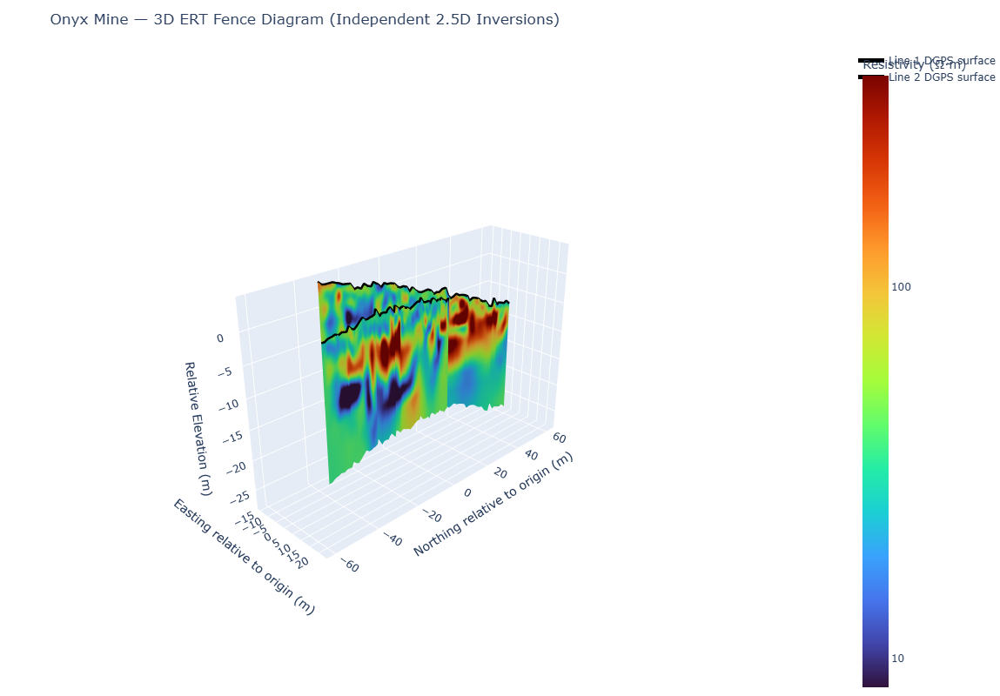

Interactive 3D model saved to:
C:\Users\molly\work\Senior-Design-Geophysical-Characterization-of-Historic-Mine-Tunnels\working_notebooks\ERT\Onyx_ERT_Interactive_3D.html


In [27]:
import plotly.graph_objects as go
from pyproj import Transformer

transformer = Transformer.from_crs("EPSG:4326", "EPSG:32613", always_xy=True)
tracks = {}
for line in (1, 2):
    p = profiles[line].sort_values("distance_m")
    e, n = transformer.transform(p["Longitude"].to_numpy(), p["Latitude"].to_numpy())
    tracks[line] = {
        "x": p["distance_m"].to_numpy(dtype=float),
        "e": np.asarray(e, dtype=float),
        "n": np.asarray(n, dtype=float),
        "h": p["elevation_m"].to_numpy(dtype=float),
    }

E0 = np.mean(np.r_[tracks[1]["e"], tracks[2]["e"]])
N0 = np.mean(np.r_[tracks[1]["n"], tracks[2]["n"]])
Z0 = np.median(np.r_[tracks[1]["h"], tracks[2]["h"]])


def make_curtain(line):
    track = tracks[line]
    out = results[line]
    n_x, n_z = 260, 101
    x = np.linspace(track["x"].min(), track["x"].max(), n_x)
    depth = np.linspace(0, DISPLAY_DEPTH_M, n_z)
    X, D = np.meshgrid(x, depth)
    east = np.interp(x, track["x"], track["e"]) - E0
    north = np.interp(x, track["x"], track["n"]) - N0
    surface_h = np.interp(x, track["x"], track["h"])
    z_display = surface_h[None, :] - D - Z0

    centers = out["mesh"].cell_centers[out["active"]]
    log_rho = -out["m_recovered"] / np.log(10.0)
    z_query = z_display + Z0 - geometry[line]["datum"]
    # Interpolation in inversion coordinates, mapped to true elevation for 3D plotting
    selected = (
        (centers[:, 0] >= x.min() - 5) & (centers[:, 0] <= x.max() + 5)
        & (centers[:, 1] >= z_query.min() - 5)
        & (centers[:, 1] <= z_query.max() + 5)
    )
    if selected.sum() < 10:
        raise ValueError(f"Line {line}: too few inverted cells to draw 3D section")
    values = griddata(centers[selected], log_rho[selected],
                      (X, z_query), method="linear")
    missing = ~np.isfinite(values)
    if missing.any():
        values[missing] = griddata(centers[selected], log_rho[selected],
                                   (X[missing], z_query[missing]), method="nearest")
    dx = (x.max() - x.min()) / (n_x - 1)
    dz = DISPLAY_DEPTH_M / (n_z - 1)
    values = gaussian_filter(values, sigma=(SMOOTH_Z_M / dz, SMOOTH_X_M / dx))
    return {"e": np.broadcast_to(east, X.shape),
            "n": np.broadcast_to(north, X.shape),
            "z": z_display, "logrho": values, "depth": D}


def cross2(a, b):
    return a[0] * b[1] - a[1] * b[0]


def surveyed_intersection(a, b):
    P = np.c_[a["e"], a["n"]]
    Q = np.c_[b["e"], b["n"]]
    for i in range(len(P) - 1):
        p, r = P[i], P[i+1] - P[i]
        for j in range(len(Q) - 1):
            q, s = Q[j], Q[j+1] - Q[j]
            det = cross2(r, s)
            if abs(det) < 1e-8:
                continue
            t = cross2(q - p, s) / det
            u = cross2(q - p, r) / det
            if 0 <= t <= 1 and 0 <= u <= 1:
                xy = p + t * r
                x1 = a["x"][i] + t * (a["x"][i+1] - a["x"][i])
                x2 = b["x"][j] + u * (b["x"][j+1] - b["x"][j])
                return xy, x1, x2
    return None


fig3d = go.Figure()
log_min, log_max = np.log10(color_min), np.log10(color_max)
color_ticks = np.arange(np.ceil(log_min), np.floor(log_max) + 1)

for line in (1, 2):
    s = make_curtain(line)
    fig3d.add_trace(go.Surface(
        x=s["e"], y=s["n"], z=s["z"],
        surfacecolor=s["logrho"],
        customdata=np.stack((10**s["logrho"], s["depth"]), axis=-1),
        colorscale="Turbo", cmin=log_min, cmax=log_max,
        opacity=1.0, showscale=(line == 2),
        colorbar=dict(title="Resistivity (Ω·m)",
                      tickvals=color_ticks,
                      ticktext=[f"{10**v:g}" for v in color_ticks]),
        name=f"Line {line}",
        hovertemplate=(
            f"Line {line}<br>E: %{{x:.1f}} m<br>N: %{{y:.1f}} m"
            "<br>Relative elevation: %{z:.1f} m"
            "<br>Depth: %{customdata[1]:.1f} m"
            "<br>Resistivity: %{customdata[0]:.1f} Ω·m<extra></extra>"
        ),
    ))
    track = tracks[line]
    fig3d.add_trace(go.Scatter3d(
        x=track["e"]-E0, y=track["n"]-N0, z=track["h"]-Z0,
        mode="lines", line=dict(color="black", width=5),
        name=f"Line {line} DGPS surface",
    ))

crossing = surveyed_intersection(tracks[1], tracks[2])
if crossing is not None:
    xy, x1, x2 = crossing
    h1 = np.interp(x1, tracks[1]["x"], tracks[1]["h"])
    h2 = np.interp(x2, tracks[2]["x"], tracks[2]["h"])
    print(f"DGPS crossing: Line 1 x={x1:.2f} m, Line 2 x={x2:.2f} m")
    print(f"Height difference at crossing: {abs(h1-h2):.2f} m")
    fig3d.add_trace(go.Scatter3d(
        x=[xy[0]-E0], y=[xy[1]-N0], z=[(h1+h2)/2-Z0],
        mode="markers", marker=dict(color="black", size=6, symbol="diamond"),
        name="DGPS intersection",
    ))
else:
    print("CAUTION: surveyed DGPS polylines do not intersect. No crossing is invented.")

e_range = np.ptp(np.r_[tracks[1]["e"], tracks[2]["e"]])
n_range = np.ptp(np.r_[tracks[1]["n"], tracks[2]["n"]])
span = max(e_range, n_range, 1.0)
fig3d.update_layout(
    title="Onyx Mine — 3D ERT Fence Diagram (Independent 2.5D Inversions)",
    height=800,
    scene=dict(
        xaxis_title="Easting relative to origin (m)",
        yaxis_title="Northing relative to origin (m)",
        zaxis_title="Relative Elevation (m)",
        aspectmode="manual",
        aspectratio=dict(x=e_range/span, y=n_range/span, z=0.65),
        camera=dict(eye=dict(x=1.5, y=-1.5, z=1.0)),
    ),
    margin=dict(l=0, r=0, t=55, b=0),
)
fig3d.show()  

from pathlib import Path

# save the interactive 3d ert model
html_path = Path.cwd() / "Onyx_ERT_Interactive_3D.html"

fig3d.write_html(
    str(html_path),
    include_plotlyjs=True,
    full_html=True,
    auto_open=False
)

print(f"Interactive 3D model saved to:\n{html_path}")

## Notes before interpretation

- **Inversion vs display:** SimPEG recovers cell-based conductivity/resistivity; contours and Gaussian smoothing only change the display. Do not infer tunnel dimensions from smooth edges.
- **Assumed uncertainties:** The relative-error and error-floor settings influence normalized RMS and inversion regularization. Without reciprocal-error analysis, RMS ≈ 1 cannot be interpreted as a definitive accuracy guarantee.
- **Depth confidence:** Uniform-looking deep areas may be dominated by the starting model or regularization. This notebook does not compute a resolution or sensitivity mask.
- **Geometry:** Verify the ABEM `x_location_type` convention and measured horizontal electrode spacing before precise dimensional claims. The 3D fence is georeferenced; the inversions themselves remain independent 2.5D sections.
- **Files:** With `SAVE_FINAL_FIGURES = True`, only `Onyx_Line1_Smoothed_Inversion.png` and `Onyx_Line2_Smoothed_Inversion.png` are saved, directly next to this notebook. No other files or folders are written by its code.